<a href="https://colab.research.google.com/github/lindo20/FACE_RECOGNITION/blob/main/FACE_RECOGNITION.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **FACE RECOGNITION**




In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import tensorflow as tf
from tqdm import tqdm_notebook as tqdm

%matplotlib inline

In [7]:
from google.colab import files

uploaded = files.upload()


Saving Dataset.zip to Dataset.zip


In [9]:
import zipfile

with zipfile.ZipFile("Dataset.zip", "r") as zip_ref:
    zip_ref.extractall("/content/")

In [10]:
image_dir = "/content/Dataset/"

In [11]:
image_paths = []
image_names = []

for image_name in tqdm(os.listdir(image_dir)):
    image_path = os.path.join(image_dir, image_name)
    image_paths.append(image_path)
    image_names.append(image_name)

/tmp/ipykernel_2867/2171331515.py:4: TqdmDeprecationWarning: This function will be removed in tqdm==5.0.0
Please use `tqdm.notebook.tqdm` instead of `tqdm.tqdm_notebook`
  for image_name in tqdm(os.listdir(image_dir)):


  0%|          | 0/1800 [00:00<?, ?it/s]

In [12]:
len(image_names), len(image_paths)

(1800, 1800)

In [13]:
image_dataframe = pd.DataFrame(index = np.arange(len(image_names)), columns = ["image_name", "path"])

i = 0
for name, path in tqdm(zip(image_names, image_paths)) :
    image_dataframe.iloc[i]["image_name"] = name
    image_dataframe.iloc[i]["path"] = path
    i = i + 1

print("Dataframe shape = ", image_dataframe.shape)

/tmp/ipykernel_2867/969072129.py:4: TqdmDeprecationWarning: This function will be removed in tqdm==5.0.0
Please use `tqdm.notebook.tqdm` instead of `tqdm.tqdm_notebook`
  for name, path in tqdm(zip(image_names, image_paths)) :


0it [00:00, ?it/s]

Dataframe shape =  (1800, 2)


/tmp/ipykernel_2867/969072129.py:5: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  image_dataframe.iloc[i]["image_name"] = name
/tmp/ipykernel_2867/969072129.py:6: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
Yo

In [14]:
image_dataframe.head()

,image_name,path
0,074_2a4ca70b.jpg,/content/Dataset/074_2a4ca70b.jpg
1,022_a0763313.jpg,/content/Dataset/022_a0763313.jpg
2,021_7b2a627c.jpg,/content/Dataset/021_7b2a627c.jpg
3,001_dfb62d96.jpg,/content/Dataset/001_dfb62d96.jpg
4,037_62d00a09.jpg,/content/Dataset/037_62d00a09.jpg


In [16]:
def get_images() :
    sample_images = []
    random_image_paths = [np.random.choice(image_dataframe["path"]) for i in range(6)]

    plt.figure(figsize = (12, 8))
    for i in range(6) :
        plt.subplot(2,3, i+1)
        image = cv2.imread(random_image_paths[i])
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        sample_images.append(image)
        plt.imshow(image, cmap = "gray")
        plt.grid(False)
    plt.tight_layout() # Automatically adjust subplot parameters to give specified padding.
    return sample_images


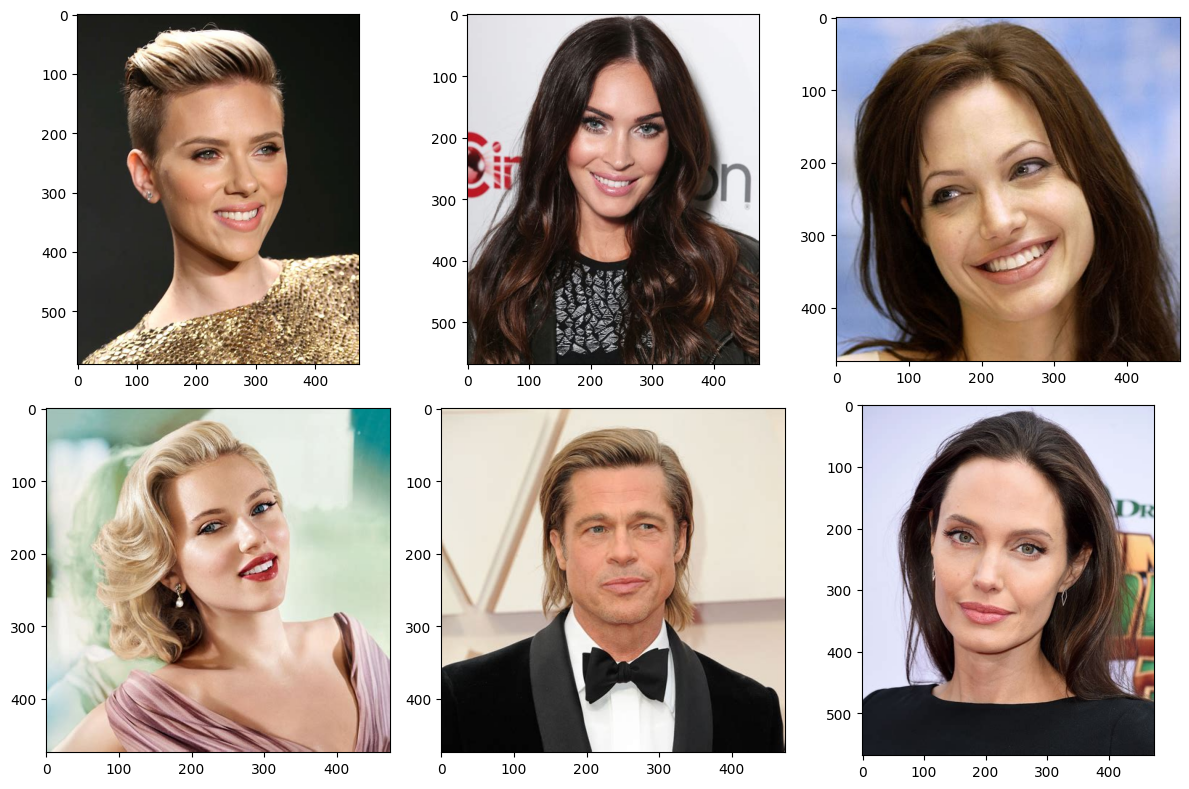

In [17]:
sample_images = []
sample_images = get_images()

In [19]:
import requests

url = "https://raw.githubusercontent.com/opencv/opencv/master/data/haarcascades/haarcascade_frontalface_default.xml"

response = requests.get(url)

if response.status_code == 200:
    with open("haarcascade_frontalface_default.xml", "wb") as file:
        file.write(response.content)

    print("File downloaded successfully.")
else:
    print(f"Failed to download the file. Status code: {response.status_code}")

File downloaded successfully.


In [20]:
import cv2

face_cascade = cv2.CascadeClassifier(
    "haarcascade_frontalface_default.xml"
)

In [21]:
def haar_cascade_detection(sample_images) :
    face_cascade = cv2.CascadeClassifier("haarcascade_frontalface_default.xml")

    for image in tqdm(sample_images) :
        gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
        faces = face_cascade.detectMultiScale(gray, 1.05, 5, 50)

        for (x_coordinate, y_coordinate, height, width) in faces :
            cv2.rectangle(image, (x_coordinate, y_coordinate), (x_coordinate + width, y_coordinate + height), (100, 0, 0), 2)

In [22]:
haar_cascade_detection(sample_images)

/tmp/ipykernel_2867/4139658062.py:4: TqdmDeprecationWarning: This function will be removed in tqdm==5.0.0
Please use `tqdm.notebook.tqdm` instead of `tqdm.tqdm_notebook`
  for image in tqdm(sample_images) :


  0%|          | 0/6 [00:00<?, ?it/s]

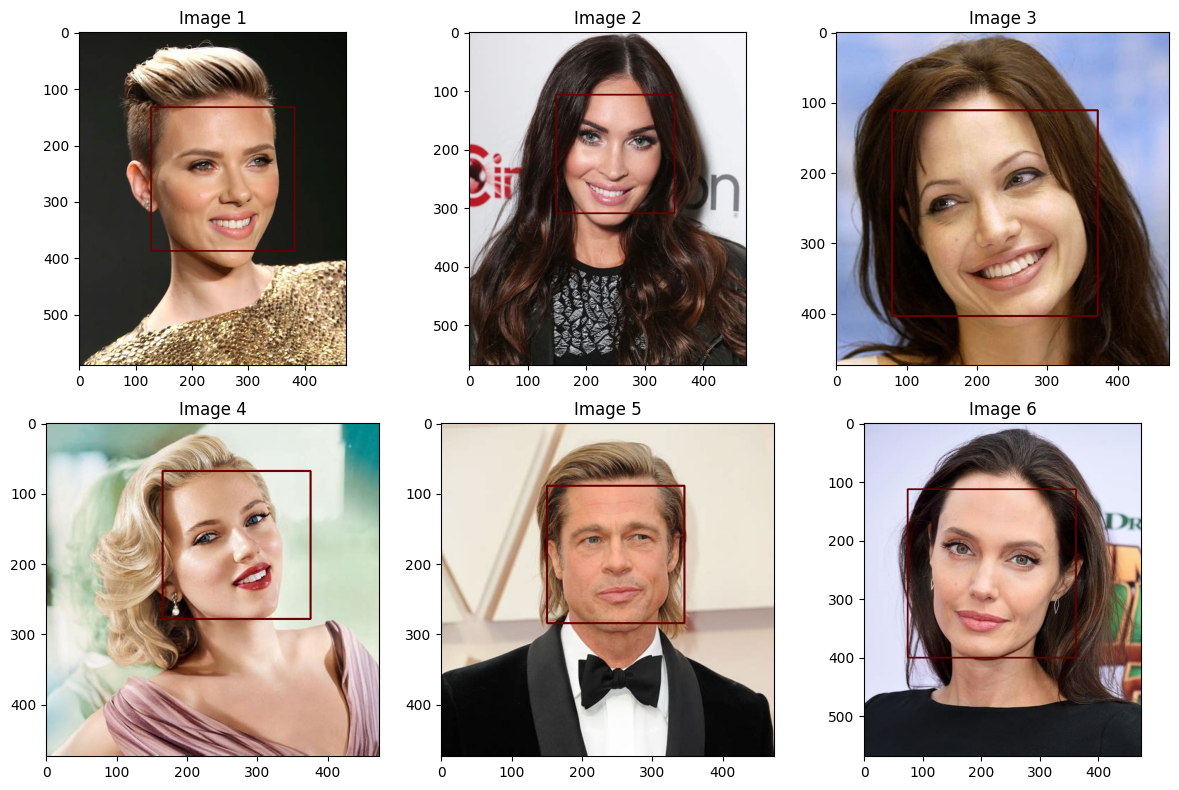

In [23]:
plt.figure(figsize = (12, 8))
for i in range(6) :
    plt.subplot(2,3, i+1)
    plt.imshow(sample_images[i], cmap = "gray")
    plt.title("Image {}".format(i+1))
    plt.grid(False)
plt.tight_layout() # Automatically adjust subplot parameters to give specified padding.

In [24]:
def load_my_image() :
    my_image_01 = cv2.imread("Dataset/001_5ef3e95c.jpg")
    my_image_01 = cv2.cvtColor(my_image_01, cv2.COLOR_BGR2RGB)

    my_image_02 = cv2.imread("Dataset/001_9adc92c2.jpg")
    my_image_02 = cv2.cvtColor(my_image_02, cv2.COLOR_BGR2RGB)

    plt.figure(figsize = (12, 8))
    plt.subplot(1,2,1)
    plt.title("The One During A Conference", fontsize = 13)
    plt.imshow(my_image_01, cmap = "gray")
    plt.grid(False)

    plt.subplot(1,2,2)
    plt.title("The One With Home Buddies!", fontsize = 13)
    plt.imshow(my_image_02, cmap = "gray")
    plt.grid(False)

    plt.tight_layout()
    return my_image_01, my_image_02

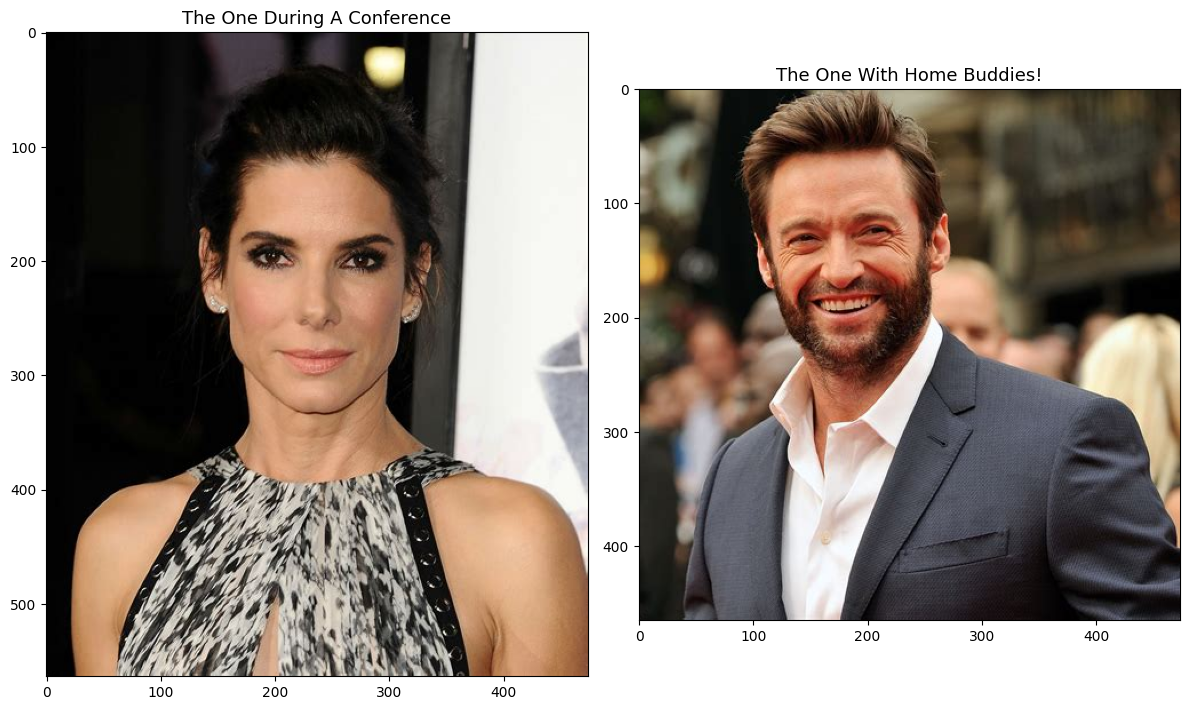

In [25]:
my_image_01, my_image_02 = load_my_image()

In [26]:
haar_cascade_detection([my_image_01, my_image_02])

/tmp/ipykernel_2867/4139658062.py:4: TqdmDeprecationWarning: This function will be removed in tqdm==5.0.0
Please use `tqdm.notebook.tqdm` instead of `tqdm.tqdm_notebook`
  for image in tqdm(sample_images) :


  0%|          | 0/2 [00:00<?, ?it/s]

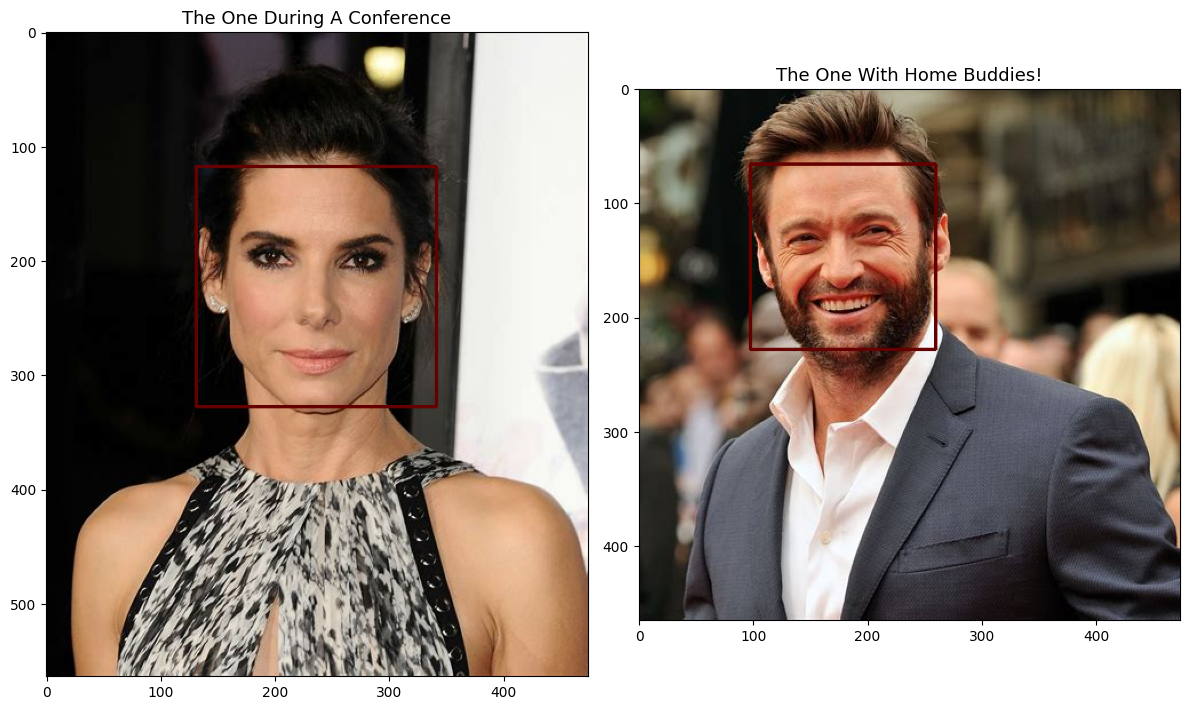

In [27]:
plt.figure(figsize = (12, 8))
plt.subplot(1,2,1)
plt.title("The One During A Conference", fontsize = 13)
plt.imshow(my_image_01, cmap = "gray")
plt.grid(False)

plt.subplot(1,2,2)
plt.title("The One With Home Buddies!", fontsize = 13)
plt.imshow(my_image_02, cmap = "gray")
plt.grid(False)

plt.tight_layout()

# **MTCNN**
The network uses a cascade structure with three networks; first the image is rescaled to a range of different sizes (called an image pyramid), then the first model (Proposal Network or P-Net) proposes candidate facial regions, the second model (Refine Network or R-Net) filters the bounding boxes, and the third model (Output Network or O-Net) proposes facial landmarks.

The model is called a multi-task network because each of the three models in the cascade (P-Net, R-Net and O-Net) are trained on three tasks, e.g. make three types of predictions; they are: face classification, bounding box regression, and facial landmark localization.

In [28]:
 pip install mtcnn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 30.4 MB/s  0:00:00


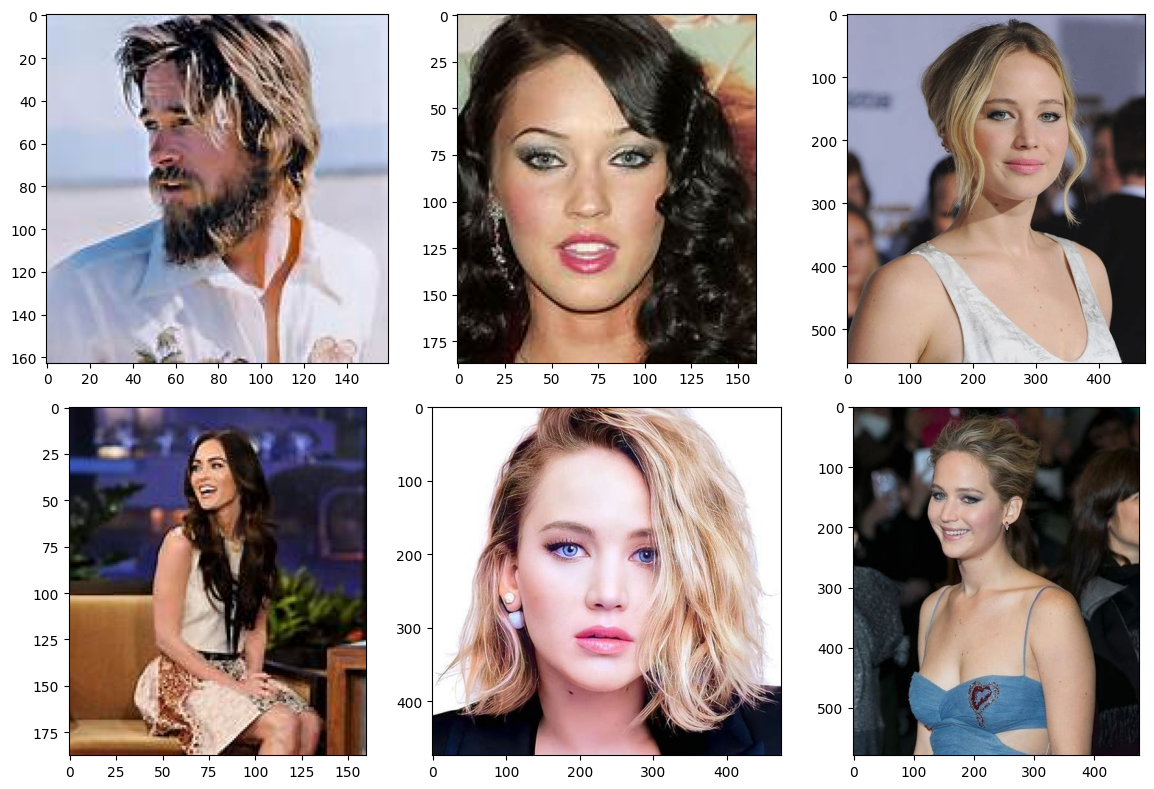

In [29]:
sample_images = get_images()

In [32]:
from mtcnn import MTCNN

detector = MTCNN()

Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.
Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.
Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.


In [33]:
print(detector)

In [34]:
def mtcnn_detector(sample_images) :
    for image in tqdm(sample_images) :
        face_location = detector.detect_faces(image)
        for face in zip(face_location) :
            x_coordinate, y_coordinate, width, height = face[0]['box']


            #face_landmarks = face[0]['keypoints']


            cv2.rectangle(image, (x_coordinate, y_coordinate), (x_coordinate + width, y_coordinate + height), (0,0,100), 2)

In [35]:
mtcnn_detector(sample_images)

/tmp/ipykernel_2867/2341347236.py:2: TqdmDeprecationWarning: This function will be removed in tqdm==5.0.0
Please use `tqdm.notebook.tqdm` instead of `tqdm.tqdm_notebook`
  for image in tqdm(sample_images) :


  0%|          | 0/6 [00:00<?, ?it/s]

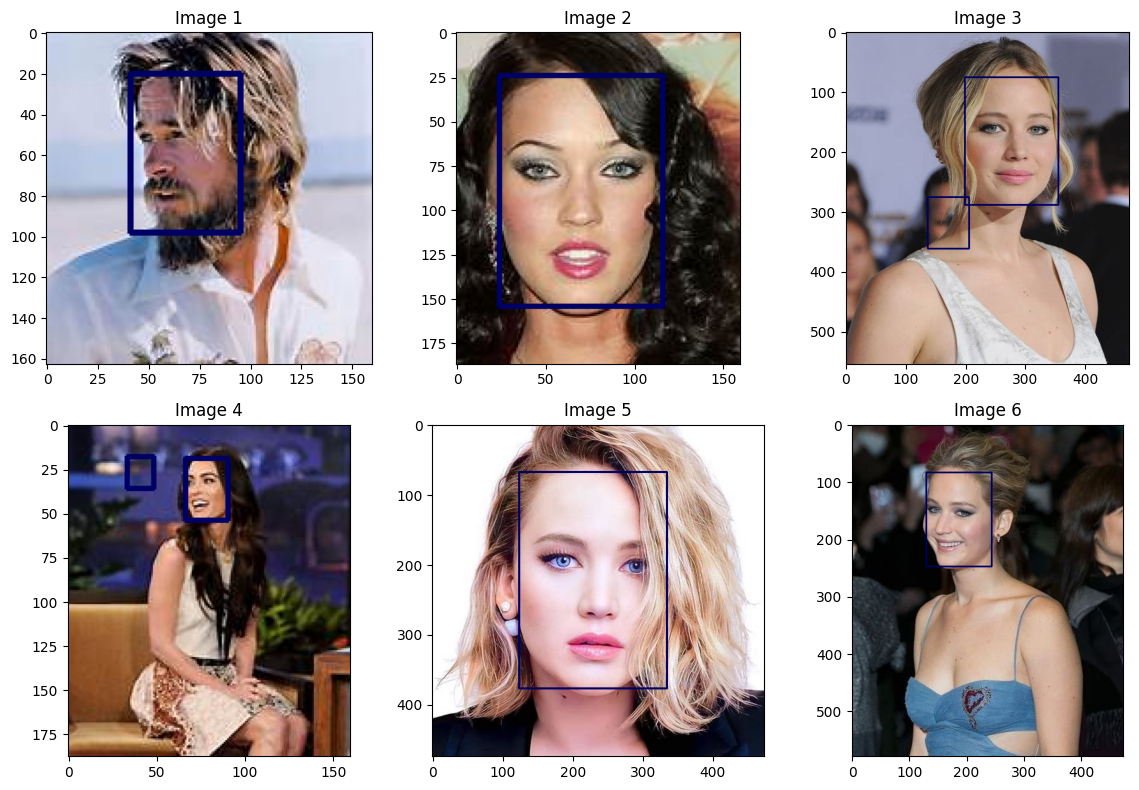

In [36]:
plt.figure(figsize = (12, 8))
for i in range(6) :
    plt.subplot(2,3, i+1)
    plt.imshow(sample_images[i], cmap = "gray")
    plt.title("Image {}".format(i+1))
    plt.grid(False)
plt.tight_layout() # Automatically adjust subplot parameters to give specified padding.

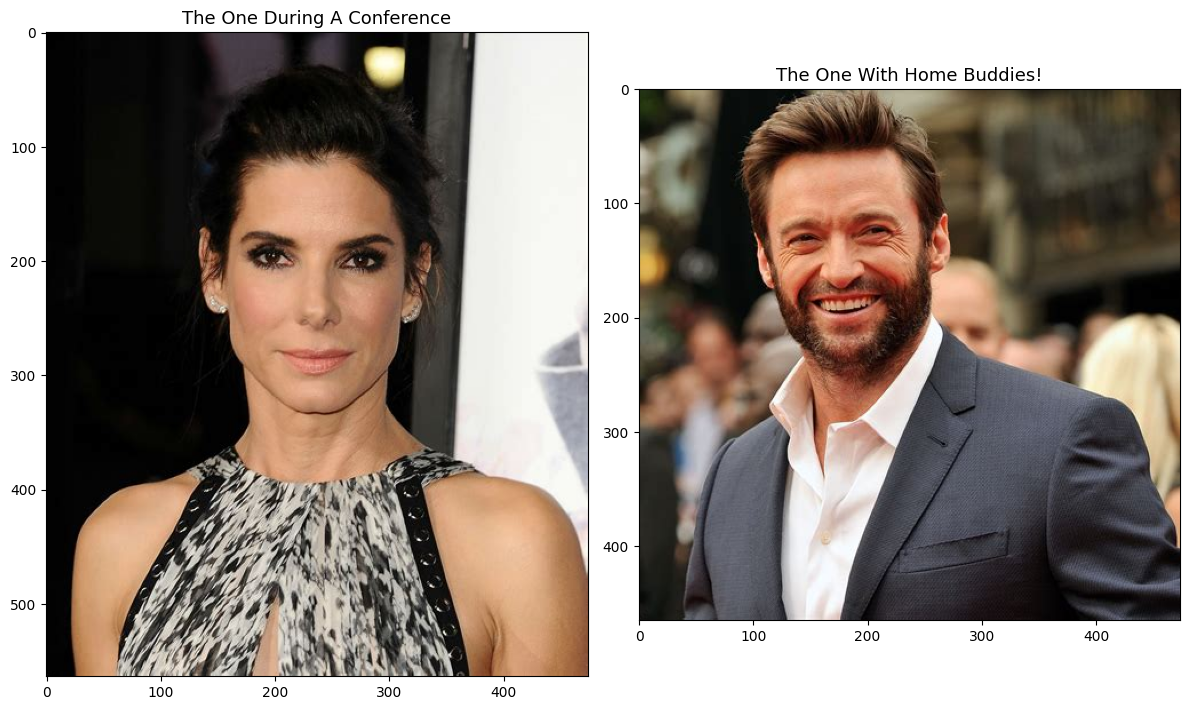

In [37]:
my_image_01, my_image_02 = load_my_image()

In [38]:
mtcnn_detector([my_image_01, my_image_02])

/tmp/ipykernel_2867/2341347236.py:2: TqdmDeprecationWarning: This function will be removed in tqdm==5.0.0
Please use `tqdm.notebook.tqdm` instead of `tqdm.tqdm_notebook`
  for image in tqdm(sample_images) :


  0%|          | 0/2 [00:00<?, ?it/s]

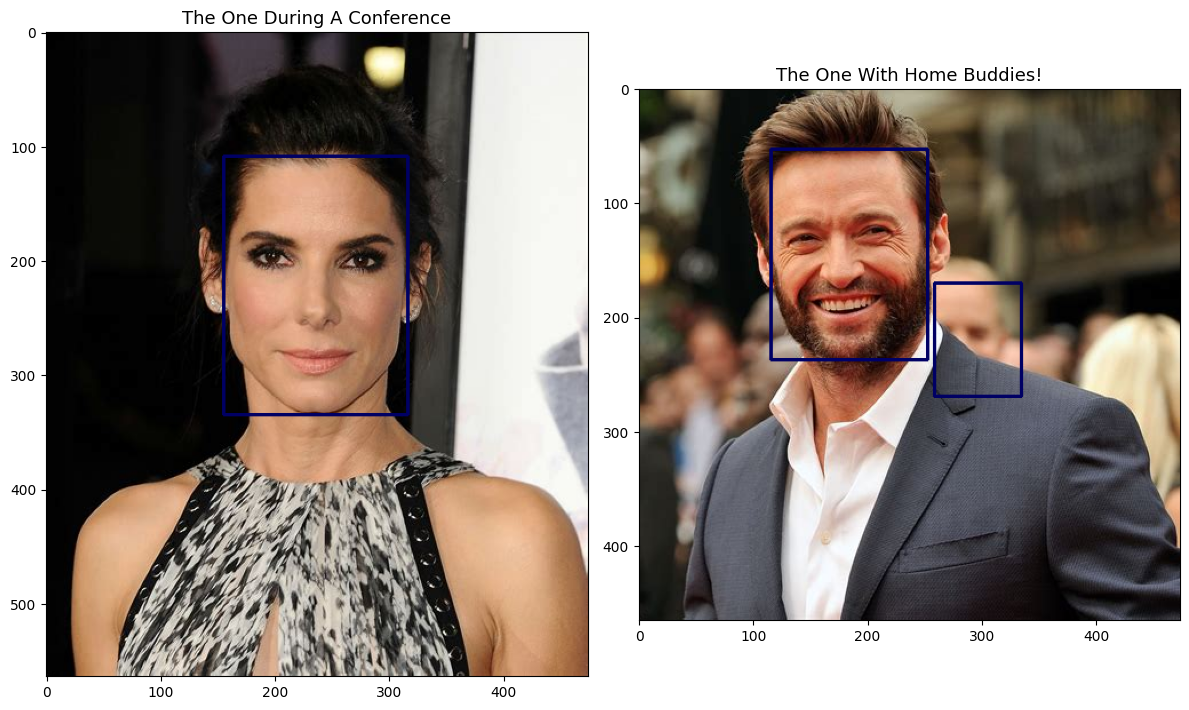

In [39]:
plt.figure(figsize = (12, 8))
plt.subplot(1,2,1)
plt.title("The One During A Conference", fontsize = 13)
plt.imshow(my_image_01, cmap = "gray")
plt.grid(False)

plt.subplot(1,2,2)
plt.title("The One With Home Buddies!", fontsize = 13)
plt.imshow(my_image_02, cmap = "gray")
plt.grid(False)

plt.tight_layout()